\
# 04 · Прогноз суточного стока Колымы: физическая модель против ML

**Моделирование гидрологических процессов · р. Колыма (пост Каменная Колыма)**

Задача — прогноз расхода воды $Q$ на сутки вперёд по осадкам $R$ метеостанции:
14 лет суточных наблюдений (2008–2021). Проверяем две стратегии:

1. **Физическая модель** — «линейный резервуар» (базовая ячейка модели
   Калинина–Милюкова): бассейн = резервуар, приток пропорционален осадкам,
   сток — запасу воды:

$$
\tau\,\frac{dQ}{dt} = a\,R(t) - Q(t)
$$

   с эмпирическими параметрами $a$ (эффективная площадь бассейна, м³/с на
   (м/сут)) и $\tau$ (время релаксации, сут), которые **калибруются
   оптимизацией**, а не вручную и не в Excel.

2. **ML-модель** — градиентный бустинг над лаговыми и календарными признаками.

Верификация честная: обучение на 2008–2015, отложенный тест 2016–2021,
сравнение с наивным инерционным прогнозом $Q_{pred}(t{+}1) = Q(t)$
(persistence). Стандартный гидрологический критерий навыка:

$$
S/\sigma_{\Delta Q} < 1,
$$

где $S$ — СКО ошибки прогноза, $\sigma_{\Delta Q}$ — СКО суточных изменений
расхода (ошибка persistence по построению); $P$ — доля оправдавшихся
прогнозов (ошибка $\le 0.674\,\sigma_{\Delta Q}$).

In [1]:
\
from pathlib import Path
import sys

ROOT = Path.cwd().parent
if str(ROOT / "src") not in sys.path:  # если пакет oahm не установлен
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})

FIG_DIR = ROOT / "figures"   # статичные иллюстрации для README
RES_DIR = ROOT / "results"   # анимации и обработанные данные
DATA_DIR = ROOT / "data"
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)


\
## Данные

Исходники — «как пришли»: расход воды в широком Excel-листе (год, день
месяца, 12 колонок-месяцев), осадки — текстовый файл метеостанции с
разделителем `;`. Загружаем их готовыми загрузчиками модуля `runoff`:
разворот «широко → длинно», парсинг дат, пропуски, пересчёт мм → м/сут.

In [2]:
\
import oahm.runoff as rr

Q = rr.load_discharge(DATA_DIR / "raw" / "kolyma_discharge_kamenka.xlsx")
R = rr.load_precipitation(DATA_DIR / "raw" / "precip_wr291058.txt")
df = rr.make_dataset(Q, R)

RES_DIR.mkdir(exist_ok=True)
df.to_csv(RES_DIR / "kolyma_daily.csv")

print(f"суточный ряд: {df.index.min().date()} — {df.index.max().date()}, "
      f"{len(df)} дней")
df.describe().round(3)

Внимание: в суточном ряде 10 разрывов (дни пропущены)
суточный ряд: 2008-01-01 — 2021-12-31, 5007 дней


,R,Q
count,5007.000,5007.000
mean,0.001,2718.582
std,0.002,3878.560
min,0.000,217.000
25%,0.000,439.000
50%,0.000,806.000
75%,0.000,3300.000
max,0.027,29900.000


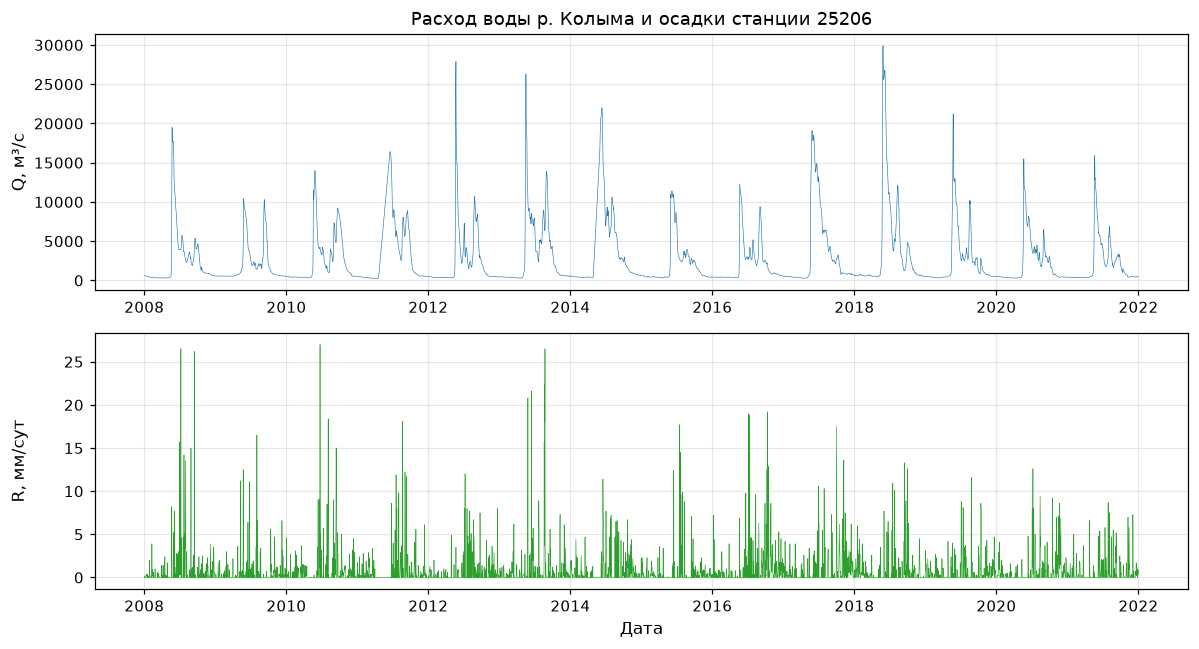

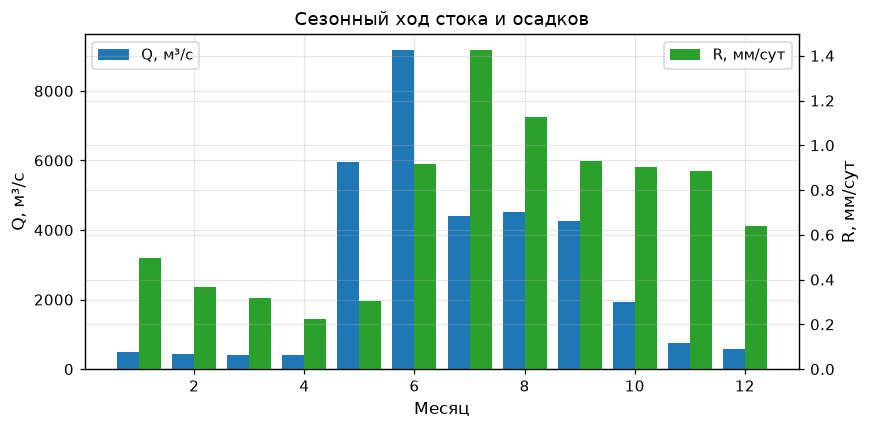

In [3]:
\
fig, axes = plt.subplots(2, 1, figsize=(11, 6))

ax = axes[0]
ax.plot(df.index, df["Q"], lw=0.4, color="tab:blue")
ax.set_ylabel("Q, м³/с")
ax.set_title("Расход воды р. Колыма и осадки станции 25206")

ax = axes[1]
ax.plot(df.index, df["R"] * 1000, lw=0.4, color="tab:green")
ax.set_ylabel("R, мм/сут")
ax.set_xlabel("Дата")

fig.align_ylabels()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_runoff_overview.png", dpi=150, bbox_inches="tight")

# сезонный ход
monthly = df.groupby(df.index.month).mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(monthly.index - 0.2, monthly["Q"], width=0.4, label="Q, м³/с")
ax2 = ax.twinx()
ax2.bar(monthly.index + 0.2, monthly["R"] * 1000, width=0.4,
        color="tab:green", label="R, мм/сут")
ax.set_xlabel("Месяц")
ax.set_ylabel("Q, м³/с")
ax2.set_ylabel("R, мм/сут")
ax.set_title("Сезонный ход стока и осадков")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_runoff_seasonality.png", dpi=150, bbox_inches="tight")

\
Гидрограф типичен для рек сибирского типа: резкое весеннее половодье
(июнь — в среднем 9 200 м³/с против ~400 м³/с зимой) формируется таянием
снега, накопленного за зиму. Дождевые паводки лета скромнее. Это сразу
подсказывает, что осадки станции — неполный вход для физической модели:
снегозапас в ней не представлен. Проверим это количественно, но сначала —
сам модельный механизм.

\
## Три разностные схемы (учебное ядро лабораторной)

ОДУ $\tau\,dQ/dt = aR - Q$ интегрируется с шагом 1 сут тремя схемами:
явный Эйлер, неявный Эйлер (приток известен на момент прогноза) и «чехарда».
Сравним их на фрагменте лета 2013 г. при одинаковых параметрах.

макс. расхождение схем: forward/backward = 275.8, forward/leapfrog = 813753.6 м³/с


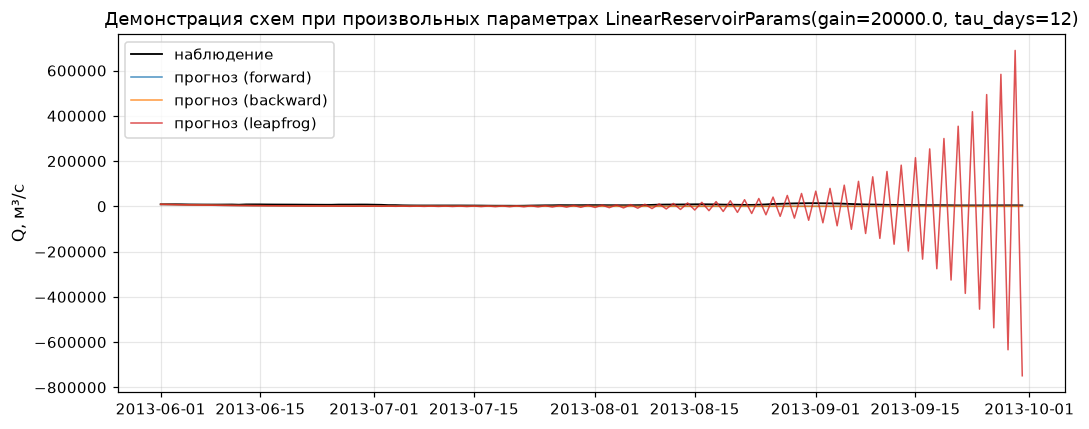

In [4]:
\
params_demo = rr.LinearReservoirParams(gain=2.0e4, tau_days=12)
seg = df.loc["2013-06-01":"2013-09-30"]
preds = {
    s: rr.simulate(seg["Q"].iloc[0], seg["R"].to_numpy(), params_demo, scheme=s)
    for s in rr.SCHEMES
}

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(seg.index, seg["Q"], "k", lw=1.2, label="наблюдение")
for (scheme, pred), color in zip(preds.items(),
                                 ("tab:blue", "tab:orange", "tab:red")):
    ax.plot(seg.index, pred[:len(seg)], lw=1, color=color,
            alpha=0.8, label=f"прогноз ({scheme})")
ax.set_ylabel("Q, м³/с")
ax.set_title(f"Демонстрация схем при произвольных параметрах {params_demo}")
ax.legend()
fig.tight_layout()

diff_fb = np.abs(preds["forward"] - preds["backward"]).max()
diff_fl = np.abs(preds["forward"] - preds["leapfrog"]).max()
print(f"макс. расхождение схем: forward/backward = {diff_fb:.1f}, "
      f"forward/leapfrog = {diff_fl:.1f} м³/с")

\
Явная и неявная схемы при $\Delta t = 1$ сут практически совпадают — как и
положено схемам первого порядка при $\Delta t \ll \tau$. Схема «чехарда»
постепенно дрейфует: для диссипативного ОДУ она имеет растущую паразитную
модулю (известный недостаток leapfrog) — наглядное напоминание, что порядок
схемы не сводится к её устойчивости. Дальше работаем с явной схемой
(`forward`).

## Калибровка параметров: сеточный поиск + уточнение градиентом

Калибровка — двумерная оптимизация RMSE на **обучающем** периоде
(2008–2015). Сетка 40×40 в пространстве $(\log a, \tau)$ даёт карту потерь
(аналог ландшафта функции потерь в ML), затем локальное уточнение L-BFGS-B.

лучшие параметры: LinearReservoirParams(gain=100000.0, tau_days=200.0), RMSE(train) = 4533 м³/с


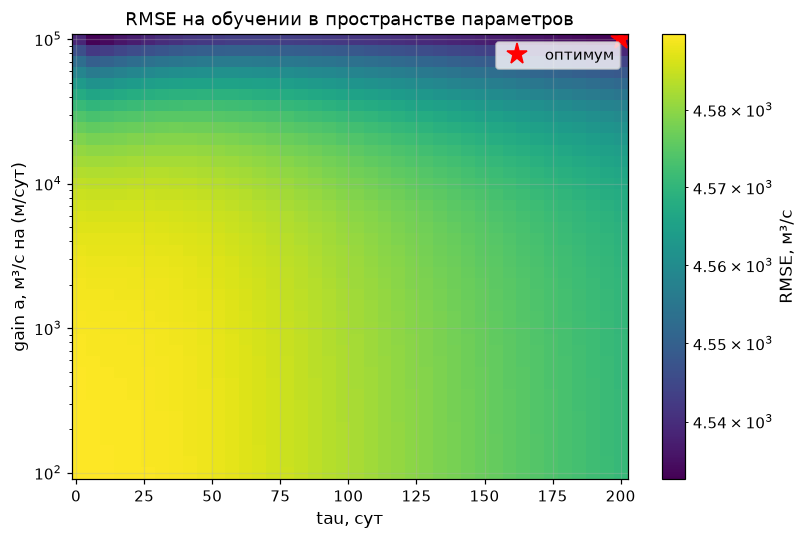

In [5]:
\
TRAIN_END = "2015-12-31"
train, test = df.loc[:TRAIN_END], df.loc["2016-01-01":]

res = rr.calibrate(
    train["Q"].to_numpy(), train["R"].to_numpy(),
    Q0=train["Q"].iloc[0],
    gain_range=(1e2, 1e5), tau_range=(1.0, 200.0),
)
print(f"лучшие параметры: {res.params}, RMSE(train) = {res.rmse:.0f} м³/с")

fig, ax = plt.subplots(figsize=(7.5, 5))
pc = ax.pcolormesh(res.grid_taus, res.grid_gains, res.loss,
                   norm="log", shading="auto", cmap="viridis")
ax.plot(res.params.tau_days, res.params.gain, "r*", ms=14, label="оптимум")
ax.set_yscale("log")
ax.set_xlabel("tau, сут")
ax.set_ylabel("gain a, м³/с на (м/сут)")
ax.set_title("RMSE на обучении в пространстве параметров")
fig.colorbar(pc, ax=ax, label="RMSE, м³/с")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_calibration_loss.png", dpi=150, bbox_inches="tight")

In [6]:
\
# сравнение разностных схем после индивидуальной калибровки каждой
rows = []
for scheme in rr.SCHEMES:
    r = (res if scheme == "forward"
         else rr.calibrate(train["Q"].to_numpy(), train["R"].to_numpy(),
                           Q0=train["Q"].iloc[0], scheme=scheme))
    pred_tr = rr.simulate(train["Q"].iloc[0], train["R"].to_numpy(),
                          r.params, scheme)[:len(train)]
    pred_te = rr.simulate(test["Q"].iloc[0], test["R"].to_numpy(),
                          r.params, scheme)[:len(test)]
    v_tr = rr.verification(train["Q"].to_numpy(), pred_tr)
    v_te = rr.verification(test["Q"].to_numpy(), pred_te)
    rows.append({
        "модель": f"линейный резервуар ({scheme})",
        "S/sig_dQ (train)": v_tr["S/sigma_dDelta"],
        "S/sig_dQ (test)": v_te["S/sigma_dDelta"],
        "P, % (train)": v_tr["P, %"],
        "P, % (test)": v_te["P, %"],
    })

# наивный инерционный прогноз
v_p_tr = rr.verification(train["Q"].to_numpy()[1:], train["Q"].to_numpy()[:-1])
v_p_te = rr.verification(test["Q"].to_numpy()[1:], test["Q"].to_numpy()[:-1])
rows.insert(0, {
    "модель": "persistence (наивный)",
    "S/sig_dQ (train)": v_p_tr["S/sigma_dDelta"],
    "S/sig_dQ (test)": v_p_te["S/sigma_dDelta"],
    "P, % (train)": v_p_tr["P, %"],
    "P, % (test)": v_p_te["P, %"],
})

verification_table = pd.DataFrame(rows).set_index("модель").round(2)
verification_table

,S/sig_dQ (train),S/sig_dQ (test),"P, % (train)","P, % (test)"
модель,,,,
persistence (наивный),1.00,1.00,91.44,88.03
линейный резервуар (forward),6.65,9.20,40.08,26.16
линейный резервуар (backward),6.65,9.20,40.08,26.16
линейный резервуар (leapfrog),7.02,9.26,26.16,16.39


\
## Отрицательный результат, и это важно

Физическая модель **не даёт навыка**: $S/\sigma_{\Delta Q} \gg 1$ — она в
разы хуже наивного инерционного прогноза. Это не ошибка кода (схемы сходятся,
оптимизация корректно минимизирует RMSE на обучении), а недостаточность
входных данных. Проверим гипотезу о «слепоте» модели к стоку напрямую —
корреляцией осадков с приростами расхода:

In [7]:
\
dQ = df["Q"].diff()
corrs = {f"R(t-{lag})" if lag else "R(t)": df["R"].shift(lag).corr(dQ)
         for lag in (0, 1, 2, 3, 5)}
corrs["sum(R, 5 сут)"] = df["R"].rolling(5).sum().corr(dQ)
corrs["sum(R, 30 сут)"] = df["R"].rolling(30).sum().corr(dQ)
pd.Series(corrs, name="corr(R, dQ)").round(3)

R(t)             -0.003
R(t-1)            0.001
R(t-2)            0.015
R(t-3)            0.017
R(t-5)            0.015
sum(R, 5 сут)     0.016
sum(R, 30 сут)   -0.038
Name: corr(R, dQ), dtype: float64

\
Корреляция нулевая: суточные осадки одной станции (61% дней — нулевые) не
объясняют колебаний стока огромного бассейна. Механика провала видна и на
сезонном ходе: пик стока приходится на июнь, когда тает снег, выпавший за
зиму, — в модели «линейного резервуара» этому процессу просто нечем
управлять. Нужны температура воздуха (модель снеготаяния) и осадки,
осреднённые по бассейну.

Замечание: в исходной лабораторной критерий качества $S/\sigma$ считался в
Excel и тоже оказался $> 1$ (1.03–1.06) — т.е. и исходный результат не
проходил проверку на навык, но это было замаскировано подгонкой параметров
под готовое число из Excel. Здесь же подбор параметров — полноценная
оптимизация, а вывод об отсутствии навыка — осознанный и объяснённый
результат.

## Мостик в ML: бустинг над лагами и календарём

Гипотеза «информации нет вообще» опровергается легко: суточный ход расхода
инерционен и сезонен. Соберём признаки из лагов $Q$ и $R$ и календаря и
обучим `HistGradientBoostingRegressor`. Ключевой приём — предсказываем не
уровень $Q$ (жирнохвостный таргет уводит бустинг к регрессии к среднему), а
его **прирост** $\Delta Q$; прогноз уровня восстанавливаем как
$Q_{t-1} + \widehat{\Delta Q}_t$.

In [8]:
\
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

def add_features(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    for lag in (1, 2, 3, 5, 7, 10):
        d[f"Q_lag{lag}"] = d["Q"].shift(lag)
    d["dQ_lag1"] = d["Q"].diff().shift(1)
    d["dQ_lag2"] = d["Q"].diff().shift(2)
    for lag in (0, 1, 2, 3, 5, 10, 30):
        d[f"R_lag{lag}"] = d["R"].shift(lag)
    d["R_sum5"] = d["R"].rolling(5).sum()
    d["R_sum30"] = d["R"].rolling(30).sum()
    doy = d.index.dayofyear
    d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    return d

features = add_features(df)
is_train = features.index <= TRAIN_END

X = features.drop(columns=["Q"])
y_delta = features["Q"].diff()          # таргет — суточный прирост
valid = y_delta.notna() & X.notna().all(axis=1)

X_tr, y_tr = X[is_train & valid], y_delta[is_train & valid]
X_te, y_te = X[~is_train & valid], y_delta[~is_train & valid]
print(f"обучение: {len(X_tr)} дней, тест: {len(X_te)} дней, "
      f"признаков: {X.shape[1]}")

model = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08,
                                      max_depth=6, random_state=42)
model.fit(X_tr, y_tr)

pred_q = features.loc[X_te.index, "Q_lag1"] + model.predict(X_te)
obs_te = features.loc[X_te.index, "Q"]
v_gbm = rr.verification(obs_te.to_numpy(), pred_q.to_numpy())
print(f"GBM (test): S/sig_dQ = {v_gbm['S/sigma_dDelta']:.3f}, "
      f"P = {v_gbm['P, %']:.1f}%")

обучение: 2787 дней, тест: 2190 дней, признаков: 20


GBM (test): S/sig_dQ = 0.909, P = 90.7%


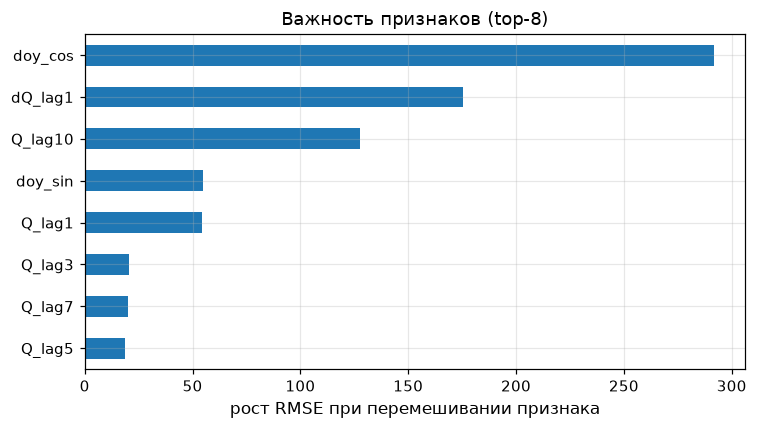

In [9]:
\
# важность признаков (permutation importance по RMSE на тесте)
pi = permutation_importance(model, X_te, y_te, n_repeats=5, random_state=0,
                            scoring="neg_root_mean_squared_error")
top = pd.Series(pi.importances_mean, index=X.columns).nlargest(8)
top.sort_values().plot.barh(figsize=(7, 4), color="tab:blue")
plt.xlabel("рост RMSE при перемешивании признака")
plt.title("Важность признаков (top-8)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_gbm_importances.png", dpi=150, bbox_inches="tight");

,S/sig_dQ (train),S/sig_dQ (test),"P, % (train)","P, % (test)"
модель,,,,
persistence (наивный),1.00,1.00,91.44,88.03
линейный резервуар (forward),6.65,9.20,40.08,26.16
линейный резервуар (backward),6.65,9.20,40.08,26.16
линейный резервуар (leapfrog),7.02,9.26,26.16,16.39
градиентный бустинг (dQ),NaN,0.91,NaN,90.68


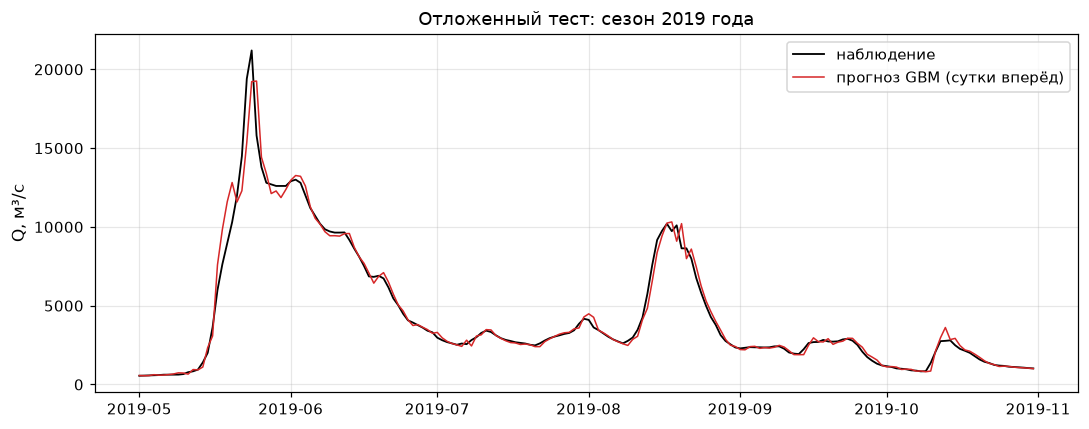

In [10]:
\
verification_table.loc["градиентный бустинг (dQ)"] = {
    "S/sig_dQ (train)": np.nan,
    "S/sig_dQ (test)": v_gbm["S/sigma_dDelta"],
    "P, % (train)": np.nan,
    "P, % (test)": v_gbm["P, %"],
}
display(verification_table.round(2))

# фрагмент прогноза: сезон 2019 года
fragment = slice("2019-05-01", "2019-10-31")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(obs_te.loc[fragment].index, obs_te.loc[fragment], "k", lw=1.2,
        label="наблюдение")
ax.plot(pred_q.loc[fragment].index, pred_q.loc[fragment], color="tab:red",
        lw=1, label="прогноз GBM (сутки вперёд)")
ax.set_ylabel("Q, м³/с")
ax.set_title("Отложенный тест: сезон 2019 года")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_gbm_forecast_2019.png", dpi=150, bbox_inches="tight")

\
## Выводы

1. Полный производственный цикл на чистом Python: загрузка «сырых»
   Excel/TXT-данных, суточный датасет, три разностные схемы, калибровка
   (сеточный поиск + L-BFGS-B), верификация против persistence на
   отложенном периоде.
2. Физическая модель не даёт навыка ($S/\sigma_{\Delta Q} \approx 7$--$9$
   на тесте против 1 у persistence):
   корреляция осадков станции с приростами стока нулевая, а главный процесс
   (снеготаяние) в модели не представлен. Отрицательный результат
   верифицирован и объяснён — в исходной лабораторной он был скрыт
   подгонкой параметров под число из Excel.
3. Бустинг над лаговыми и календарными признаками восстанавливает навык:
   $S/\sigma_{\Delta Q} = 0.91 < 1$, доля оправдавшихся прогнозов 90.7%
   против 88.0% у persistence. Навык скромный — и закономерно: без
   данных о температуре и снегозапасе потолок прогноза ограничен инерцией
   и сезонностью стока.
4. Дорожная карта: осадки, осреднённые по бассейну (гридд-данные), температура
   + degree-day модель снеготаяния,ML-модель на этих же физических признаках
   (вместо «слепых» лагов) — сочетание физической структуры и ML.

\
## Приложение: цена циклов по строкам pandas

В исходной лабораторной прогноз накапливался пошаговым `pd.concat` по
строкам (O(n²) на каждый шаг). Тот же расчёт на preallocated-массиве
`numpy`:

In [11]:
\
import time

def simulate_old_style(Q0, R_series, params, n_days=2000):
    '''Как в исходном ноутбуке лабораторной: pd.concat по одной строке.'''
    R_local = R_series.iloc[:n_days]
    acc = pd.DataFrame(dtype=float)
    q = Q0
    stamps = R_local.index
    for i, date in enumerate(stamps):
        q_new = q + (params.gain * R_local.iloc[i] - q) / params.tau_days
        acc = pd.concat([acc, pd.DataFrame({"Q": [q_new]}, index=[date])])
        q = q_new
    return acc

n = 1500
R_sub = train["R"]
t0 = time.perf_counter()
simulate_old_style(train["Q"].iloc[0], R_sub, res.params, n_days=n)
t_old = time.perf_counter() - t0

t0 = time.perf_counter()
rr.simulate(train["Q"].iloc[0], R_sub.to_numpy()[:n], res.params)
t_new = time.perf_counter() - t0

print(f"pd.concat-цикл: {t_old:.2f} с | numpy-массив: {t_new*1000:.1f} мс "
      f"| ускорение ×{t_old / max(t_new, 1e-9):,.0f}")

pd.concat-цикл: 0.35 с | numpy-массив: 1.0 мс | ускорение ×353
